<center>

## ARHITEKTURE NEURONSKIH MREŽA
## Vježba 2 <br>**Perceptron**



</center>



📣 **PERCEPTRON** je osnovna građevna jedinica *svake neuronske mreže*.

#### ANALOGIJA S BIOLOŠKIM NEURONOM


Perceptron je zapravo *pojednostavljeni, matematički model* biološkog neurona.

Neuron | Perceptron
-|-
Prima signale od drugih neurona (*dendrite*) | Prima $n$ ulaznih signala
Obrađuje signale u jezgri (*nucleus*) | Vrši izračun nad tim ulaznim signalima
Šalje informaciju drugim stanicama (*axon terminal*) | Provlači rezultat tog izračuna kroz **nelinearnu** funkciju koja daje jedan izlaz $\to$ **aktivaciju** perceptrona za dane ulaze

<img src = 'https://drive.google.com/uc?id=18vtm0yiLk-4lchtXL8IHA0AkUzD7MotG' width='400px'/> | <img src='https://drive.google.com/uc?id=12ephGygcm8GuqVNk4SoqJMcgqybqU7IP' width='400px' />

## Kako radi perceptron?

---

Oznake:

- $x_i$ je $i$-ti ulaz
- $w_i$ je težinski faktor $i$-tog ulaza
- $\varphi$ je ***nelinearna*** funkcija koju nazivamo **aktivacijskom funkcijom**

Algoritam:

1. Množimo sve $x_i$ s $w_i$
2. Zbrojimo sve umnoške $x_i\cdot w_i$
3. Taj zbroj ulazi u aktivacijsku funkciju
4. Aktivacijska funkcija proizvodi izlaz - **aktivaciju** neurona

### Čemu služi aktivacijska funkcija?

- Aktivacijska funkcija je **nelinearna** funkcija; njen graf nije pravac.
- Nelinearna aktivacijska funkcija omogućava višeslojnim perceptronima učenje kompleksnijih preslikavanja.
- Ovdje koristimo vrlo jednostavnu aktivacijsku funkciju - **step funkciju**:



$$S(x)=
\begin{cases}
    1, & \text{ako je } x\geq 0\\
    0, & \text{u protivnom}.
\end{cases}$$
<br><br>
<center>
<img src = 'https://upload.wikimedia.org/wikipedia/commons/a/af/Asymptote_Heaviside_function.png' width='300px'/>
</center>

**Napomena**

---

 Neka su
- $\boldsymbol{x} = (x_1, x_2, \dots, x_n) \in \mathbb{R}^n$ vektor ulaznih vrijednosti
- $\boldsymbol{w} = (w_1, w_2, \dots, w_n) \in \mathbb{R}^n$ vektor odgovarajućih težina.

Tada vrijednost koju računa neuron i šalje u aktivacijsku funkciju možemo dobiti kao skalarni produkt $$\langle \boldsymbol{x}, \boldsymbol{w}\rangle = \sum\limits_i^n x_iw_i \in \mathbb{R}.$$
 Dakle, aktivacija neurona bit će jednaka $\varphi(\langle \boldsymbol{x}, \boldsymbol{w}\rangle)$.
 <br><br>

 **Matrična notacija:**
 <br><br>
 $$\boldsymbol{x} = \begin{bmatrix}x_1 \\ x_2 \\ \vdots \\ x_n\end{bmatrix}, \quad \boldsymbol{w} = \begin{bmatrix} w_1 \\ w_2 \\ \vdots \\ w_n \end{bmatrix}\implies   \text{aktivacija} =  \varphi(\boldsymbol{x}^T \boldsymbol{w}).$$



## Implementacija u Pythonu

### Bazna klasa

In [4]:
""" Do not change. """

from abc import ABC, abstractmethod
import numpy as np

class Perceptron(ABC):
    """ Base class for our perceptrons."""
    def __init__(self, lr=0.5, epochs=100):
        """ Constructor. """
        self.learning_rate = lr
        self.epochs = epochs
        self.weights = None
    def evaluate(self, X, y):
        """ Get prediction accuracy against a test set. """
        predictions = self.predict(X)
        return np.count_nonzero(predictions == y) / y.shape[0]          # točnost: broj točnih/ukupno
    def predict(self, X):
        """ Predict labels for a list of inputs. """
        predictions = []
        for x in X:
            prediction = 0 if np.dot(self.weights, x) < 0 else 1        # implementacija step funkcije
            predictions.append(prediction)
        return np.array(predictions)
    @abstractmethod
    def fit(self):
        """ Abstract training method. """
        pass

### Jednostavni perceptron

In [5]:
""" Do not change. """

class SimplePerceptron(Perceptron):
    """
    Simple perceptron.
    Extends the abstract class above by implementing fit().
    """
    def fit(self, X, y):
        """ Simple perceptron training. """
        self.weights = np.random.randn(X.shape[1])
        self.weight_history = []
        for epoch in range(self.epochs):
            # the training data is shuffled every epoch
            the_data = list(zip(X, y))
            np.random.shuffle(the_data)
            for x, label in the_data:
                # attempt prediction
                prediction = 0 if np.dot(self.weights, x) < 0 else 1
                # if the prediction fails, update the weights
                if prediction != label:
                    update = self.learning_rate * (label - prediction) * x
                    self.weights += update
            self.weight_history.append(np.copy(self.weights))

### AveragedPerceptron
> *Zadaća: Zadatak 1*

In [6]:
class AveragedPerceptron(Perceptron):
    """
    Averaged perceptron.
    Must extend the abstract class by implementing fit().
    The fit() for AveragedPerceptron is very similar to the one by SimplePerceptron.
    """
    def fit(self, X, y):
        # YOUR CODE HERE
        pass

### [Breast Cancer Wisconsin (Diagnostic)](https://archive.ics.uci.edu/ml/datasets/Breast+Cancer+Wisconsin+(Diagnostic))
    - 569 instanci podataka
    - 30 numeričkih značajki/dijagnostičkih mjerenja

In [7]:
import numpy as np

In [8]:
""" Do not change. """
# the breast cancer dataset
from sklearn.datasets import load_breast_cancer
data = load_breast_cancer()

In [9]:
print(data.DESCR)

.. _breast_cancer_dataset:

Breast cancer wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is Worst Radius.

    - 

In [10]:
X = np.array(data['data'])  # data points
print(f'X shape: {X.shape}')
y = np.array(data['target'])  # labels
print('Labels: {}'.format(np.unique(y)))
print('Class names: {}'.format(data['target_names']) )

X shape: (569, 30)
Labels: [0 1]
Class names: ['malignant' 'benign']


In [11]:
b = np.ones_like(y)  # bias
X = np.column_stack((X, b))  # gets glued to data

In [12]:
b.shape

(569,)

In [13]:
b

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

In [14]:
from tqdm import tqdm
# x- and y-axis values for plotting
xs = []
# ys_averaged = []  # UNCOMMENT THIS LINE
ys_simple = []

# stack the data together for shuffling
the_data = np.column_stack((X, y))
# 50% of the data for training, 50% for testing
cutoff = len(the_data) // 2

# test these epoch numbers
for epochs in tqdm(range(0, 151, 5)):
    xs.append(epochs)
    # scores_averaged = []  # UNCOMMENT THIS LINE
    scores_simple = []

    # do 10 runs for each epoch
    for experiments in range(0, 10):

        # prepare training and test data
        # the data is randomly shuffled for each experiment
        np.random.shuffle(the_data)
        # bez zadnja dva retka (bias i labele)
        X_train = the_data[:cutoff,:-2] # -1 ako zelim uhvatiti 1icu za bias
        y_train = the_data[:cutoff,-1]
        X_test = the_data[cutoff:,:-2]  # -1 ako zelim uhvatiti 1icu za bias
        y_test = the_data[cutoff:,-1]

        # create the perceptrons
        # averaged_perceptron = AveragedPerceptron(epochs=epochs)  # UNCOMMENT THIS LINE
        simple_perceptron = SimplePerceptron(epochs=epochs)
        # train the perceptrons with training data
        # averaged_perceptron.fit(X_train, y_train)  # UNCOMMENT THIS LINE
        simple_perceptron.fit(X_train, y_train)
        # evaluate the perceptrons against test data
        # scores_averaged.append(averaged_perceptron.evaluate(X_test, y_test))  # UNCOMMENT THIS LINE
        scores_simple.append(simple_perceptron.evaluate(X_test, y_test))

    # store the experiment means for plotting
    # ys_averaged.append(np.mean(scores_averaged))  # UNCOMMENT THIS LINE
    ys_simple.append(np.mean(scores_simple))

# print("averaged: {:.2f}".format(ys_averaged[-1]))  # UNCOMMENT THIS LINE
print("\nsimple: {:.2f}".format(ys_simple[-1]))

100%|██████████| 31/31 [00:10<00:00,  2.86it/s]


simple: 0.87


In [15]:
simple_perceptron.weights

array([ 2.43925660e+03,  1.11036581e+03,  1.20721347e+04,  3.31199369e+03,
        1.09336698e+01, -7.33199043e+01, -1.28995522e+02, -4.90532300e+01,
        1.43717331e+01,  1.06280828e+01,  4.90605609e+01,  1.31128789e+02,
       -1.01735709e+02, -3.64985455e+03, -1.48534913e+00, -2.03447186e+01,
       -2.77252136e+01, -6.30359663e+00,  4.42475708e-02, -1.80615094e-01,
        2.61494692e+03, -4.18235382e+01,  9.63443349e+03, -5.34083746e+03,
        5.09274006e+00, -2.62356711e+02, -3.68016306e+02, -8.76676548e+01,
       -3.50379781e+00, -1.26242236e+01])

In [16]:
simple_perceptron.weights.shape

(30,)

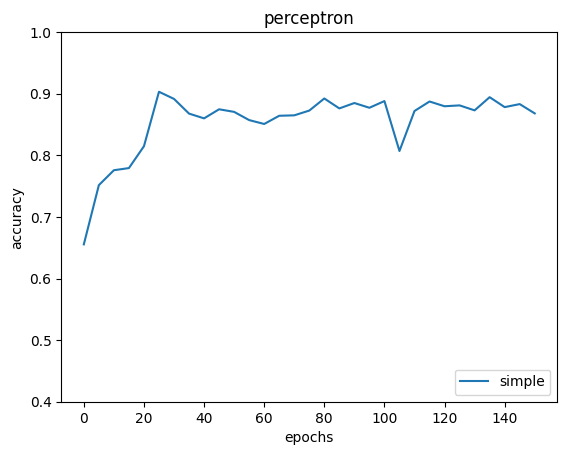

In [17]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.title("perceptron")
plt.xlabel("epochs")
plt.ylabel("accuracy")
plt.ylim(0.4, 1)

# plt.plot(xs, ys_averaged, label="averaged")  # UNCOMMENT THIS LINE
plt.plot(xs, ys_simple, label="simple")
plt.legend(loc=4)
plt.show()

###  Primjer s 2D ulazom

Možemo vizualizirati skup podataka u ravnini - 2D prostoru. U ovom slučaju klasifikacija se svodi na "povlačenje" pravca koji dijeli jednu klasu od druge (*binarna klasifikacija*).

<br>

**Zašto pravac?**
>  Perceptron može klasificirati samo linearno separabilne skupove zato što implementira skalarni produkt težina $\boldsymbol{w}$ i vektora $\boldsymbol{x}$ tj. *linearnu kombinaciju* značajki $x_i$.
>
> ➡️ "Povlačenje" najboljeg pravca odgovara pronalaženju najboljih težina.
> <br> <br>
> U višedimenzionalnim prostorima perceptron pronalazi **hiperravninu** - poopćenje pravca.
> - Hiperravnina uvijek dijeli prostor na dva dijela. Zbog toga ovakav jednostavni perceptron možemo koristiti samo za probleme binarne klasifikacije.




In [18]:
from sklearn.datasets import make_blobs

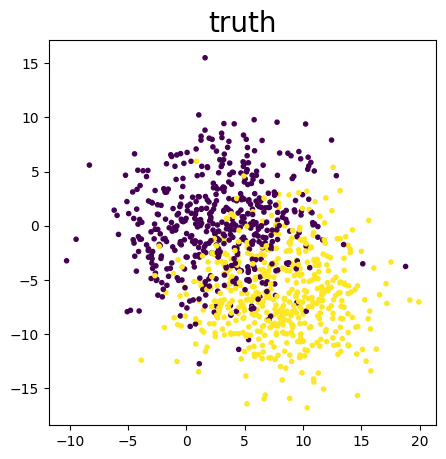

In [19]:
X, y = make_blobs(n_features=2, centers=2, n_samples=1000, random_state=18, cluster_std=4)

fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.scatter(X[:, 0], X[:, 1], c=y, marker=".")
ax.set_title('truth', fontsize=20)
plt.show()

In [20]:
new_simple = SimplePerceptron()
b = np.ones_like(y)  # bias
X_with_bias = np.column_stack((X, b))  # gets glued to data
new_simple.fit(X_with_bias, y)

In [21]:
new_simple.weights

array([  5.56604373,  -5.50831595, -33.32604226])

In [22]:
print(new_simple.evaluate(X_with_bias, y))
y_predicted = new_simple.predict(X_with_bias)

0.815


In [23]:
def calc_hyperplane(X, w):
    return np.ravel([-(w[2] + x * w[0]) / w[1] for x in X])

In [24]:
calc_hyperplane([0,10], new_simple.weights)

array([-6.05013267,  4.05466848])

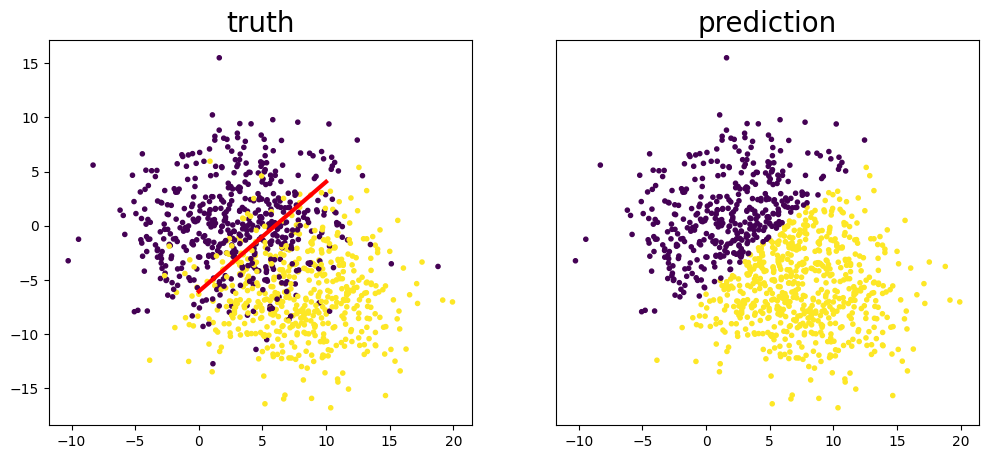

In [25]:
# Visualize results
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(X[:, 0], X[:, 1], c=y, marker=".")
ax[0].plot([0, 10], calc_hyperplane([0,10], new_simple.weights), lw=3, c='red')
ax[0].set_title('truth', fontsize=20)

ax[1].scatter(X[:, 0], X[:, 1], c=y_predicted, marker=".")
ax[1].set_xlim(ax[0].get_xlim())
ax[1].set_ylim(ax[0].get_ylim())
ax[1].set_yticks([])
ax[1].set_title('prediction', fontsize=20,)

plt.show()

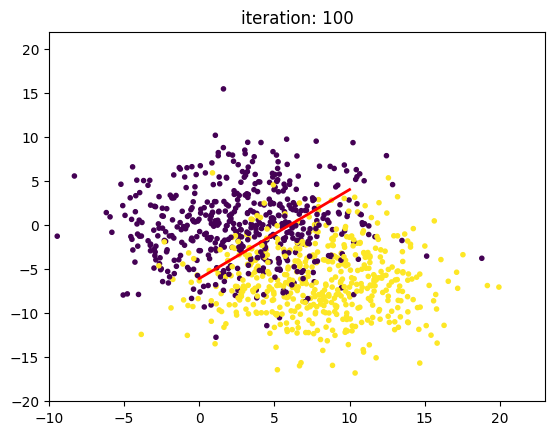

In [26]:
import time
from IPython import display

fig, ax = plt.subplots()

for i, the_weights in enumerate(new_simple.weight_history):
    plt.cla()
    # ax.axhline(y=0, color='k', alpha=0.1)
    # ax.axvline(x=0, color='k', alpha=0.1)
    plt.scatter(X[:, 0], X[:, 1], c=y, marker=".")
    plt.plot([0, 10], calc_hyperplane([0,10], the_weights), lw=2, c='red')
    plt.xlim([-10,23])
    plt.ylim([-20, 22])
    plt.title("iteration: {}".format(i+1))
    display.display(plt.gcf())
    display.clear_output(wait=True)
    time.sleep(1)